In [4]:
from pathlib import Path
import ast
import pandas as pd
import numpy as np

DATA_DIR = Path("../data/raw")
LABELS_PATH = DATA_DIR / "labeled_anomalies.csv"

df_labels = pd.read_csv(LABELS_PATH)

print(f"Toplam Kanal Sayısı: {len(df_labels)}")
print("\n--- Uzay Aracı Bazında Kanal Dağılımı ---")
print(df_labels["spacecraft"].value_counts())

print("\n--- İlk 5 Satır ---")
display(df_labels.head())

Toplam Kanal Sayısı: 82

--- Uzay Aracı Bazında Kanal Dağılımı ---
spacecraft
SMAP    55
MSL     27
Name: count, dtype: int64

--- İlk 5 Satır ---


,chan_id,spacecraft,anomaly_sequences,class,num_values
0,P-1,SMAP,"[[2149, 2349], [4536, 4844], [3539, 3779]]","[contextual, contextual, contextual]",8505
1,S-1,SMAP,"[[5300, 5747]]",[point],7331
2,E-1,SMAP,"[[5000, 5030], [5610, 6086]]","[contextual, contextual]",8516
3,E-2,SMAP,"[[5598, 6995]]",[point],8532
4,E-3,SMAP,"[[5094, 8306]]",[point],8307


In [5]:
def inspect_channel(chan_id: str):
    train_path = DATA_DIR / "train" / f"{chan_id}.npy"
    test_path = DATA_DIR / "test" / f"{chan_id}.npy"
    
    train_data = np.load(train_path)
    test_data = np.load(test_path)
    
    print(f"================ Kanal: {chan_id} ================")
    print(f"Train Shape: {train_data.shape} | Test Shape: {test_data.shape}")
    print(f"Veri Tipi (dtype): {train_data.dtype}")
    print(f"Eksik Değer (NaN) Var mı? -> Train: {np.isnan(train_data).any()}, Test: {np.isnan(test_data).any()}")
    print(f"Sonsuz Değer (Inf) Var mı? -> Train: {np.isinf(train_data).any()}, Test: {np.isinf(test_data).any()}")
    
    # 0. Sütun (Telemetri) vs Diğer Sütunlar (Komutlar)
    telemetry_train = train_data[:, 0]
    num_commands = train_data.shape[1] - 1
    print(f"Telemetri Sinyali Değer Aralığı [Min, Max]: [{telemetry_train.min():.4f}, {telemetry_train.max():.4f}]")
    print(f"Komut Sütun Sayısı: {num_commands}")
    if num_commands > 0:
        unique_cmd_vals = np.unique(train_data[:, 1:])
        print(f"Komut Sütunlarındaki Benzersiz Değerler: {unique_cmd_vals}")
    print()

# Bir SMAP ve bir MSL kanalını inceleyelim
inspect_channel("P-1")  # SMAP
inspect_channel("M-1")  # MSL

================ Kanal: P-1 ================
Train Shape: (2872, 25) | Test Shape: (8505, 25)
Veri Tipi (dtype): float64
Eksik Değer (NaN) Var mı? -> Train: False, Test: False
Sonsuz Değer (Inf) Var mı? -> Train: False, Test: False
Telemetri Sinyali Değer Aralığı [Min, Max]: [-1.0000, 1.0000]
Komut Sütun Sayısı: 24
Komut Sütunlarındaki Benzersiz Değerler: [0. 1.]

================ Kanal: M-1 ================
Train Shape: (2209, 55) | Test Shape: (2277, 55)
Veri Tipi (dtype): float64
Eksik Değer (NaN) Var mı? -> Train: False, Test: False
Sonsuz Değer (Inf) Var mı? -> Train: False, Test: False
Telemetri Sinyali Değer Aralığı [Min, Max]: [-0.9161, 2.4923]
Komut Sütun Sayısı: 54
Komut Sütunlarındaki Benzersiz Değerler: [0. 1.]



Grafik kaydedildi: ..\reports\figures\E-2_anomalies.png


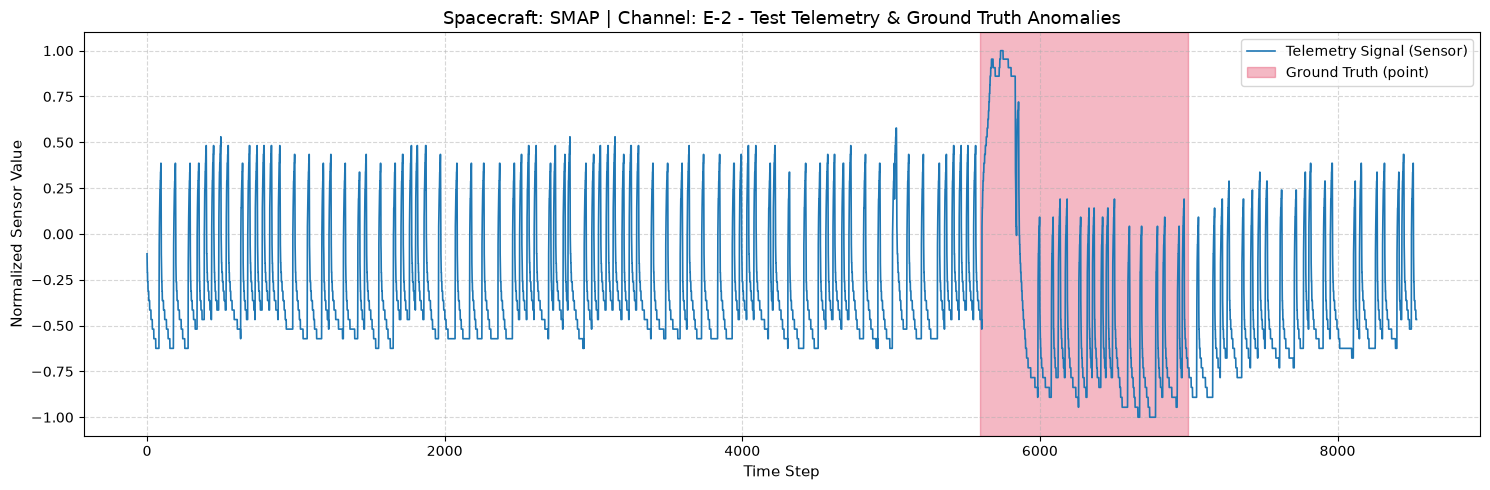

Grafik kaydedildi: ..\reports\figures\M-1_anomalies.png


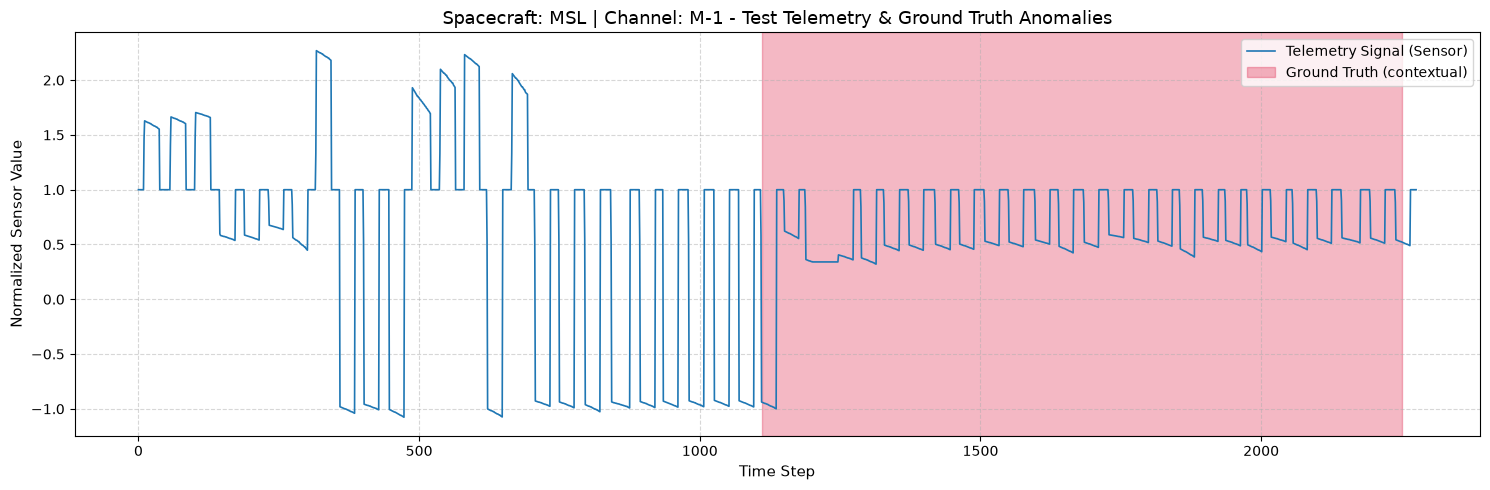

In [6]:
import matplotlib.pyplot as plt
import ast

def parse_classes(class_str: str) -> list[str]:
    """Tırnaksız [contextual, point] metinlerini temiz bir Python listesine çevirir."""
    cleaned = str(class_str).strip("[]")
    return [c.strip() for c in cleaned.split(",") if c.strip()]

def plot_channel_anomalies(chan_id: str, save_fig: bool = True):
    # 1. Test verisini yükle
    test_data = np.load(DATA_DIR / "test" / f"{chan_id}.npy")
    telemetry = test_data[:, 0]
    
    # 2. Etiketleri CSV'den filtrele ve güvenli parse et
    row = df_labels[df_labels["chan_id"] == chan_id].iloc[0]
    spacecraft = row["spacecraft"]
    anomaly_ranges = ast.literal_eval(row["anomaly_sequences"])
    anomaly_types = parse_classes(row["class"])
    
    # 3. Görselleştirme
    plt.figure(figsize=(15, 5))
    plt.plot(telemetry, label="Telemetry Signal (Sensor)", color="#1f77b4", linewidth=1.2)
    
    # Anomali bölgelerini kırmızı ile işaretle
    first_flag = True
    for (start, end), a_type in zip(anomaly_ranges, anomaly_types):
        lbl = f"Ground Truth ({a_type})" if first_flag else None
        plt.axvspan(start, end, color="crimson", alpha=0.3, label=lbl)
        first_flag = False
        
    plt.title(f"Spacecraft: {spacecraft} | Channel: {chan_id} - Test Telemetry & Ground Truth Anomalies", fontsize=13)
    plt.xlabel("Time Step", fontsize=11)
    plt.ylabel("Normalized Sensor Value", fontsize=11)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(loc="upper right")
    plt.tight_layout()
    
    # 4. Şartname gereği reports/figures altına kaydet
    if save_fig:
        fig_path = Path("../reports/figures") / f"{chan_id}_anomalies.png"
        plt.savefig(fig_path, dpi=150)
        print(f"Grafik kaydedildi: {fig_path}")
        
    plt.show()

# --- BURASI FONKSİYON DIŞI (En soldan başlar) ---
plot_channel_anomalies("E-2")


# Mars Science Laboratory (MSL) gezgininin M-1 kanalını görselleştir
plot_channel_anomalies("M-1")